In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.max_columns', None)

df = pd.read_csv('goemotions.csv')

emotion_cols = ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval',
 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief',
'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral'
]

df['created_utc'] = pd.to_datetime(df['created_utc'], unit='s')
df[emotion_cols] = df[emotion_cols].astype('int8')
df['text_length'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().str.len()

display(df.head())
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Date range: {df['created_utc'].min().date()} to {df['created_utc'].max().date()}")
print(f"Unique raters: {df['rater_id'].nunique()}")
print(f"Unique comments: {df['id'].nunique()}")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Unique subreddits: {df['subreddit'].nunique()}")

,text,id,author,subreddit,link_id,parent_id,created_utc,rater_id,example_very_unclear,admiration,amusement,anger,annoyance,approval,caring,confusion,curiosity,desire,disappointment,disapproval,disgust,embarrassment,excitement,fear,gratitude,grief,joy,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral,text_length,word_count
0,That game hurt.,eew5j0j,Brdd9,nrl,t3_ajis4z,t1_eew18eq,2019-01-25 01:50:39,1,False,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,15,3
1,>sexuality shouldn’t be a grouping category I...,eemcysk,TheGreen888,unpopularopinion,t3_ai4q37,t3_ai4q37,2019-01-21 15:22:49,37,True,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,127,21
2,"You do right, if you don't care then fuck 'em!",ed2mah1,Labalool,confessions,t3_abru74,t1_ed2m7g7,2019-01-02 11:15:44,37,False,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,46,10
3,Man I love reddit.,eeibobj,MrsRobertshaw,facepalm,t3_ahulml,t3_ahulml,2019-01-20 06:17:34,18,False,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,18,4
4,"[NAME] was nowhere near them, he was by the Fa...",eda6yn6,American_Fascist713,starwarsspeculation,t3_ackt2f,t1_eda65q2,2019-01-05 06:10:01,2,False,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,52,10


Shape: 211225 rows, 39 columns
Date range: 2019-01-01 to 2019-01-31
Unique raters: 82
Unique comments: 58011
Missing values: 0
Unique subreddits: 483


**Creating a positive emotion variable**

In [23]:
pos_emotions = [
    'admiration', 'amusement', 'approval', 'caring',
     'curiosity', 'desire', 
     'excitement',  'gratitude', 
    'joy', 'love',  'optimism', 'pride',  'relief'
]

df["positive_count"] = df[pos_emotions].sum(axis=1)

df["positive_count"].describe()


count    211225.00000
mean          0.51243
std           0.66003
min           0.00000
25%           0.00000
50%           0.00000
75%           1.00000
max           7.00000
Name: positive_count, dtype: float64

Below, I've shown the distribution of the positive emotion distribution. We see a slight right skew.

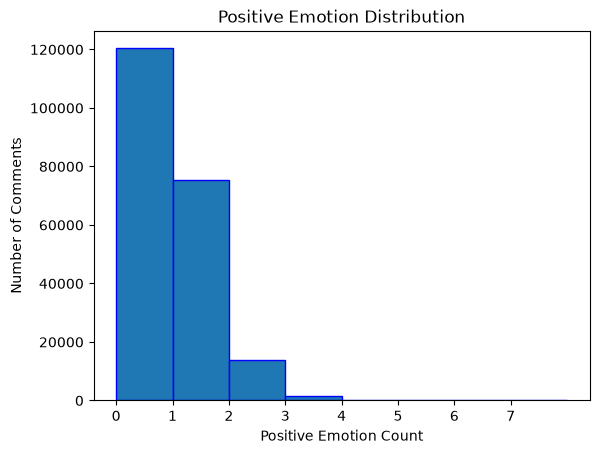

In [24]:
plt.hist(df["positive_count"], bins = 8, range = (0, 8), edgecolor = "blue")
plt.xticks(range(0, 8))
plt.xlabel("Positive Emotion Count")
plt.ylabel("Number of Comments")
plt.title("Positive Emotion Distribution")
plt.show()

**Conclusion: Spearman R: Is positive emotion count related to text length?**

H0: There is no relationship between a comment's positive emotion count and it's word length.
HA: There is a relationship between positive emotion count and the word length. 

We used Spearman's rank correlation because our positive emotion score is a discrete (ranked) count, as is word count data. Furthermore, the positive emotion count data slightly skewed, which is why Spearman's is better to use than Pearson's R in this case.

In [25]:
import scipy
from scipy.stats import pearsonr

res = scipy.stats.spearmanr(df["positive_count"], df["word_count"])
print(res.pvalue)
print(res.statistic)

0.007354390651226695
0.005832015809230355


Since the p-value is less than .05, we reject the null hypothesis, and there is statistically significant evidence that comments with a higher positive count are slightly longer because the r value is greater than 0 and the p-value is significant. This difference is shown in the boxplot below.

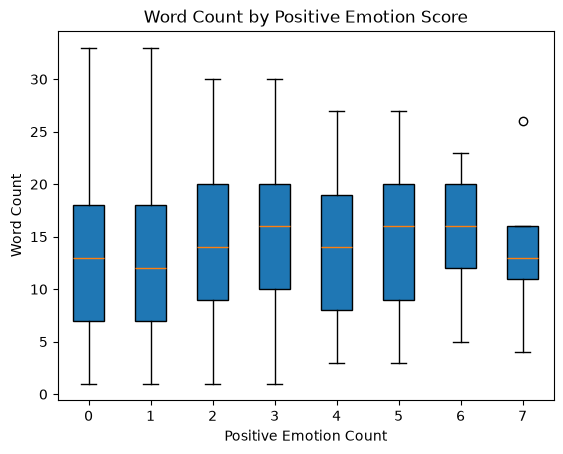

In [26]:
df["positive_count_category"] = df["positive_count"].astype("category")

anger_group= df.loc[df["anger"] == 1, "text_length"].dropna()
optimistic_group = df.loc[df["optimism"] == 1, "text_length"].dropna()

groups = []
for i in range(8):
    groups.append(df.loc[df["positive_count"] == i, "word_count"].dropna())
#df.boxplot(column = "word_count", by = "positive_count", grid = True)
plt.boxplot(groups, tick_labels = ["0", "1", "2", "3", "4", "5", "6", "7"], patch_artist = True)
plt.xlabel("Positive Emotion Count")
plt.ylabel("Word Count")
plt.title("Word Count by Positive Emotion Score")
plt.show()

**Conclusion: One-Tailed T-Test: Are angry comments shorter than optimistic comments?**

H0: The average length of an angry comment is equal to the average length of an optimistic comment.
HA: The average length of an angry comment is less than the average length of an optimistic comment. 

We use a one-tailed t-test because we were testing a directional hypothesis comparing a numeric outcome (text length) of two independent groups (anger vs. optimism).

In [27]:
import scipy
anger_group= df.loc[df["anger"] == 1, "text_length"].dropna()
optimistic_group = df.loc[df["optimism"] == 1, "text_length"].dropna()
last_t, p_val = scipy.stats.ttest_ind(anger_group, optimistic_group, alternative = "less")
print("anger mean", anger_group.mean())
print("optimistic mean", optimistic_group.mean())
print("p-value", p_val) 

anger mean 68.29391390400792
optimistic mean 80.12989099254159
p-value 6.040882310138295e-101


Since the p-value is less than .05, we reject the null hypothesis, as there is statistically significant evidence that angry comments are shorter than optimistc comments. This difference is shown in the boxplot below.

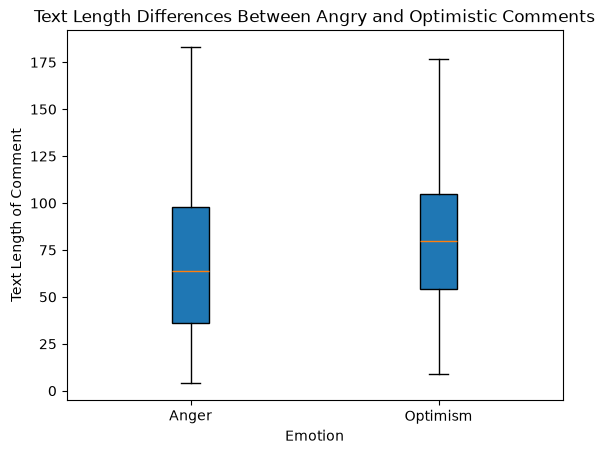

In [28]:
plt.boxplot([anger_group, optimistic_group], tick_labels = ["Anger", "Optimism"], patch_artist = True)
plt.xlabel("Emotion")
plt.ylabel("Text Length of Comment")
plt.title("Text Length Differences Between Angry and Optimistic Comments")
plt.show()